# 03 · Exploración complementaria: factores del dominio y metadatos
**Proyecto Visión por Computador — CRISP-DM etapa 2, exploración complementaria**

Atiende dos aspectos que la exploración inicial dejó abiertos: *identificar los elementos del dominio que afectan la identificación del color* y *correlacionar el color con los metadatos (género, tipo de producto…)*. Además profundiza en el análisis cualitativo de las imágenes.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from core import config
from core.datos import decodificar
from core.color import lab_a_rgb

config.RUTA_FIGURAS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "savefig.dpi": 150})
rng = np.random.default_rng(config.SEMILLA)

def guardar(nombre):
    plt.savefig(config.RUTA_FIGURAS / f"{nombre}.png")

from scipy.stats import chi2_contingency, kruskal
from core.preparacion import cargar_prendas, cargar_tabla
ok, df, msg = cargar_prendas(); print(msg)
bytes_por_id = df.set_index("id")["imagen_bytes"]
tabla, proto = cargar_tabla()
t = tabla[tabla["tiene_objetivo"]].copy()
t["multicolor"] = t["multicolor"].astype(bool)
t["hue"] = np.degrees(np.arctan2(t["b_obj"], t["a_obj"])) % 360

21,361 prendas en el alcance textil (Apparel)


## 1. Elementos del dominio que afectan la identificación del color
El color que registra una cámara **no es una propiedad solo de la tela**: es el producto de la luz, la tela y el sensor. Desde la colorimetría textil, los factores son:

| Factor del dominio | Efecto sobre el color en la foto | Cómo se mide en este dataset | Mitigación en el proyecto |
|---|---|---|---|
| **Iluminante** (temperatura de color, luz cálida o fría) | Desplaza a\*/b\* de todo el objeto | Croma del fondo blanco, ganancias de balance de blancos | Balance de blancos (Von Kries); entrenamiento con iluminantes simulados |
| **Exposición / brillo** | Cambia L\*; satura blancos y empasta negros | L\* del fondo, histogramas | Normalización; aumento de exposición en entrenamiento |
| **Sombras y pliegues de la tela** | Una sola tela produce un rango de L\* | Desviación de L\* dentro del color dominante | k-means: el objetivo es el grupo dominante, no el promedio |
| **Textura, brillo y acabado** (satinado, denim, punto) | Reflejos especulares y microsombras | Dispersión intra-prenda, casos cualitativos | Mediana robusta; paleta |
| **Estampados y varios colores** | No existe un único color | Participación y ΔE del segundo color | Regla de multicolor + paleta |
| **Persona, piel y otras prendas** | Contaminan la medición | Fracción de píxeles de piel/cabello | Segmentación de la prenda |
| **Fondo** | En fotos reales no es blanco; engaña al balance de blancos | Tipo de fondo en el contexto real | Gray-world o modelo entrenado con fondos variados |
| **Cámara, compresión y resolución** | Gamut sRGB, artefactos JPEG, 60×80 px | Calidad JPEG simulada | Prueba de robustez |
| **Metamerismo y sustrato** | Dos telas iguales bajo una luz difieren bajo otra; la fibra cambia el resultado del tinte | No observable en fotos RGB | Límite declarado: el laboratorio valida con espectrofotómetro |

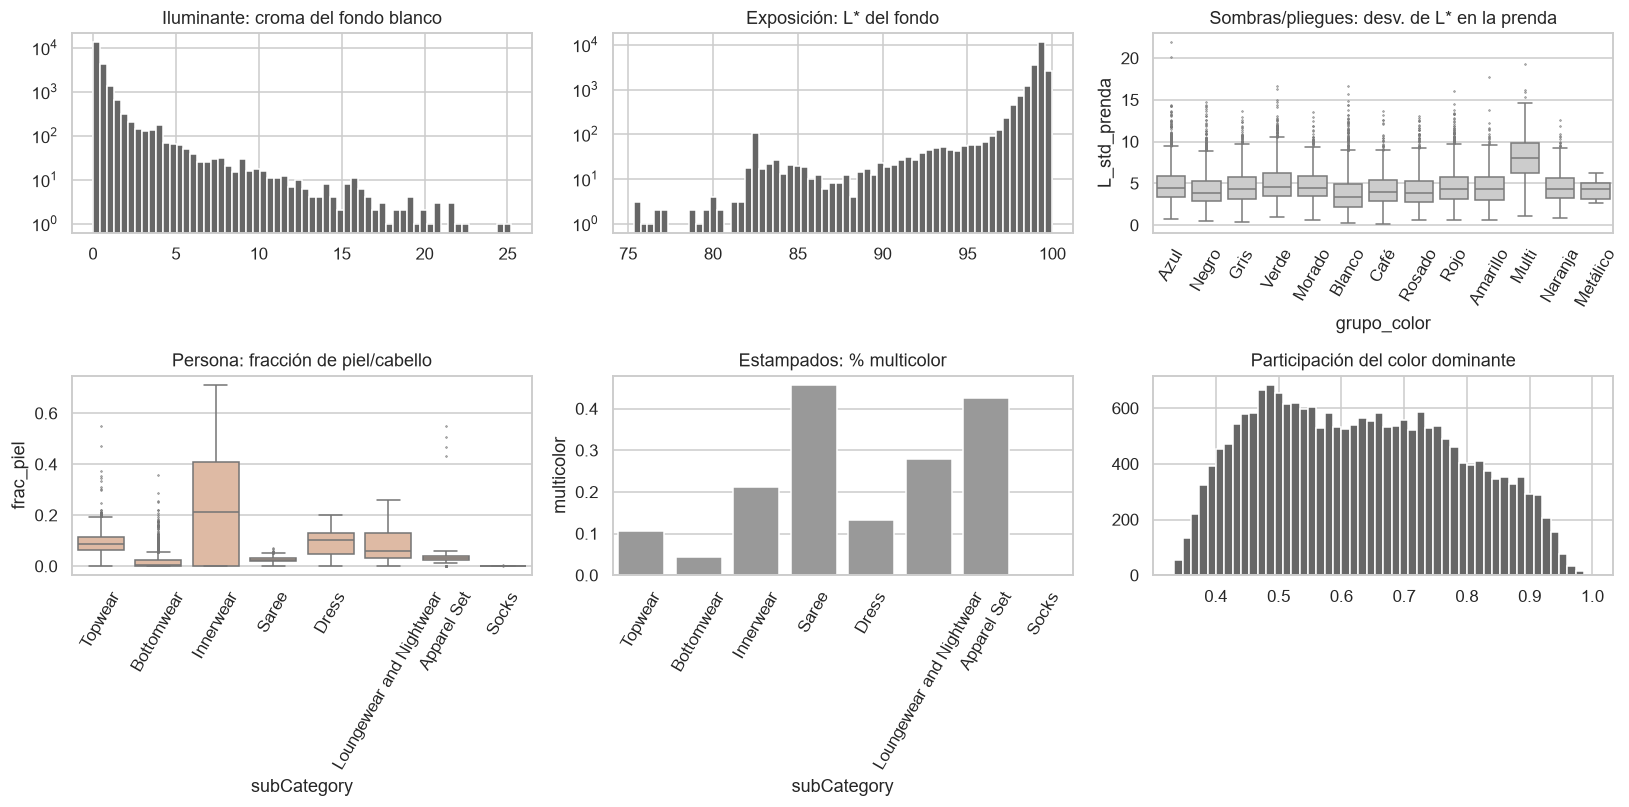

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
axes[0, 0].hist(t["croma_fondo"].dropna(), bins=60, color="0.4"); axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Iluminante: croma del fondo blanco")
axes[0, 1].hist(t["L_fondo"].dropna(), bins=60, color="0.4"); axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Exposición: L* del fondo")
sns.boxplot(data=t, x="grupo_color", y="L_std_prenda", ax=axes[0, 2], color="0.8", fliersize=.5)
axes[0, 2].tick_params(axis="x", rotation=60); axes[0, 2].set_title("Sombras/pliegues: desv. de L* en la prenda")
sns.boxplot(data=t, x="subCategory", y="frac_piel", ax=axes[1, 0], color="#e8b89a", fliersize=.5)
axes[1, 0].tick_params(axis="x", rotation=60); axes[1, 0].set_title("Persona: fracción de piel/cabello")
sns.barplot(data=t, x="subCategory", y="multicolor", ax=axes[1, 1], color="0.6", errorbar=None)
axes[1, 1].tick_params(axis="x", rotation=60); axes[1, 1].set_title("Estampados: % multicolor")
axes[1, 2].hist(t["part_1"], bins=50, color="0.4"); axes[1, 2].set_title("Participación del color dominante")
plt.tight_layout(); guardar("p3_factores_dominio"); plt.show()

In [3]:
# ¿Cuánto cambia el color medido si NO se corrige el balance de blancos? (efecto del iluminante)
from core.objetivo_color import medir_color_prenda
from core.segmentacion import segmentar_dataset
from skimage import color as skcolor
mapas = segmentar_dataset(df)
m = t.sample(800, random_state=3)
sin = np.array([[o["L_obj"], o["a_obj"], o["b_obj"]] for o in
                (medir_color_prenda(decodificar(bytes_por_id[p]), mapas[p], m.at[p, "subCategory"], corregir_blancos=False) for p in m.index)])
de_wb = skcolor.deltaE_ciede2000(sin, m[["L_obj", "a_obj", "b_obj"]].to_numpy())
print(f"Efecto del balance de blancos en fotos de catálogo: ΔE mediano {np.median(de_wb):.2f}, p90 {np.percentile(de_wb, 90):.2f}")
print(f"Correlación (Spearman) entre croma del fondo y ese ΔE: {pd.Series(de_wb).corr(m['croma_fondo'].reset_index(drop=True), method='spearman'):.2f}")

Efecto del balance de blancos en fotos de catálogo: ΔE mediano 0.00, p90 0.59
Correlación (Spearman) entre croma del fondo y ese ΔE: 0.77


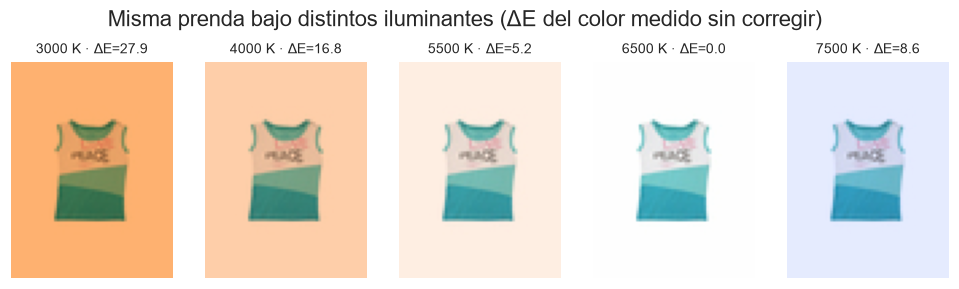

In [4]:
# Efecto de un iluminante real sobre una misma prenda: 3.000 K vs 6.500 K vs 7.500 K
from core.perturbaciones import rgb_de_temperatura
from core.objetivo_color import srgb_a_lineal, lineal_a_srgb
pid = t[(t["baseColour"] == "Blue") & (t["subCategory"] == "Topwear")].index[5]
rgb = decodificar(bytes_por_id[pid]).astype(float) / 255
fig, axes = plt.subplots(1, 5, figsize=(11, 3))
for ax, k in zip(axes, [3000, 4000, 5500, 6500, 7500]):
    img = lineal_a_srgb(srgb_a_lineal(rgb) * rgb_de_temperatura(k))
    o = medir_color_prenda((img * 255).astype(np.uint8), mapas[pid], "Topwear", corregir_blancos=False)
    de = skcolor.deltaE_ciede2000([o["L_obj"], o["a_obj"], o["b_obj"]], t.loc[pid, ["L_obj", "a_obj", "b_obj"]].to_numpy(float))
    ax.imshow(img); ax.set_title(f"{k} K · ΔE={de:.1f}", fontsize=9); ax.axis("off")
plt.suptitle("Misma prenda bajo distintos iluminantes (ΔE del color medido sin corregir)")
guardar("p3_iluminantes"); plt.show()

## 2. Correlación del color con los metadatos
Se mide la asociación entre el **grupo de color** y cada metadato con la **V de Cramér** (0 = independientes, 1 = totalmente asociados; prueba χ²). Luego se comparan las variables continuas (L\*, croma, matiz) entre géneros, temporadas y usos.

In [5]:
def cramer_v(x, y):
    tabla_c = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(tabla_c)
    n = tabla_c.values.sum(); r, k = tabla_c.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), p

base = t[~t["grupo_color"].isin(["Multi"])]
metas = ["gender", "subCategory", "articleType", "usage", "season", "year"]
filas = []
for mtd in metas:
    v, p = cramer_v(base["grupo_color"], base[mtd].astype(str))
    filas.append({"metadato": mtd, "V_Cramer": v, "p_valor": p, "categorias": base[mtd].nunique()})
asoc = pd.DataFrame(filas).set_index("metadato").sort_values("V_Cramer", ascending=False)
display(asoc.style.format({"V_Cramer": "{:.3f}", "p_valor": "{:.1e}"}))

,V_Cramer,p_valor,categorias
metadato,,,
gender,0.176,0.0e+00,5
articleType,0.171,0.0e+00,56
subCategory,0.116,0.0e+00,8
usage,0.106,5.4e-255,7
year,0.080,1.4e-213,11
season,0.062,6.2e-34,4


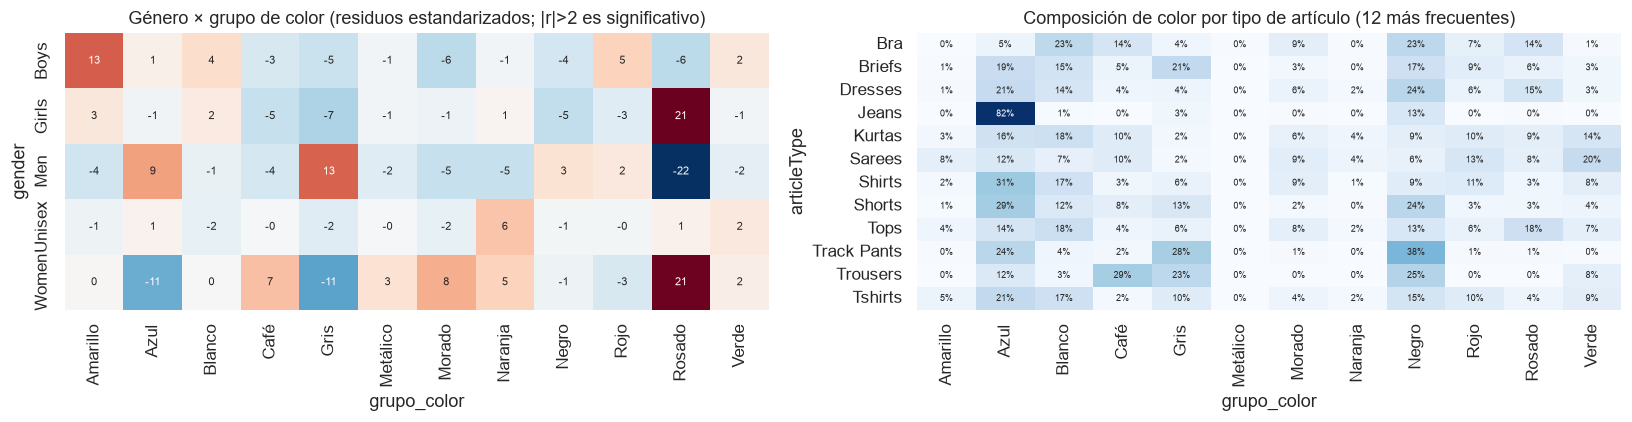

In [6]:
# Residuos estandarizados: qué combinación género × color está sobre/subrepresentada
ct = pd.crosstab(base["gender"], base["grupo_color"])
chi2, p, dof, esperado = chi2_contingency(ct)
residuos = (ct - esperado) / np.sqrt(esperado)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.heatmap(residuos, cmap="RdBu_r", center=0, annot=True, fmt=".0f", annot_kws={"size": 7}, ax=axes[0], cbar=False)
axes[0].set_title("Género × grupo de color (residuos estandarizados; |r|>2 es significativo)")
top_art = base["articleType"].value_counts().head(12).index
ct2 = pd.crosstab(base.loc[base["articleType"].isin(top_art), "articleType"], base["grupo_color"], normalize="index")
sns.heatmap(ct2, cmap="Blues", annot=True, fmt=".0%", annot_kws={"size": 6}, ax=axes[1], cbar=False)
axes[1].set_title("Composición de color por tipo de artículo (12 más frecuentes)")
plt.tight_layout(); guardar("p3_metadatos_color"); plt.show()

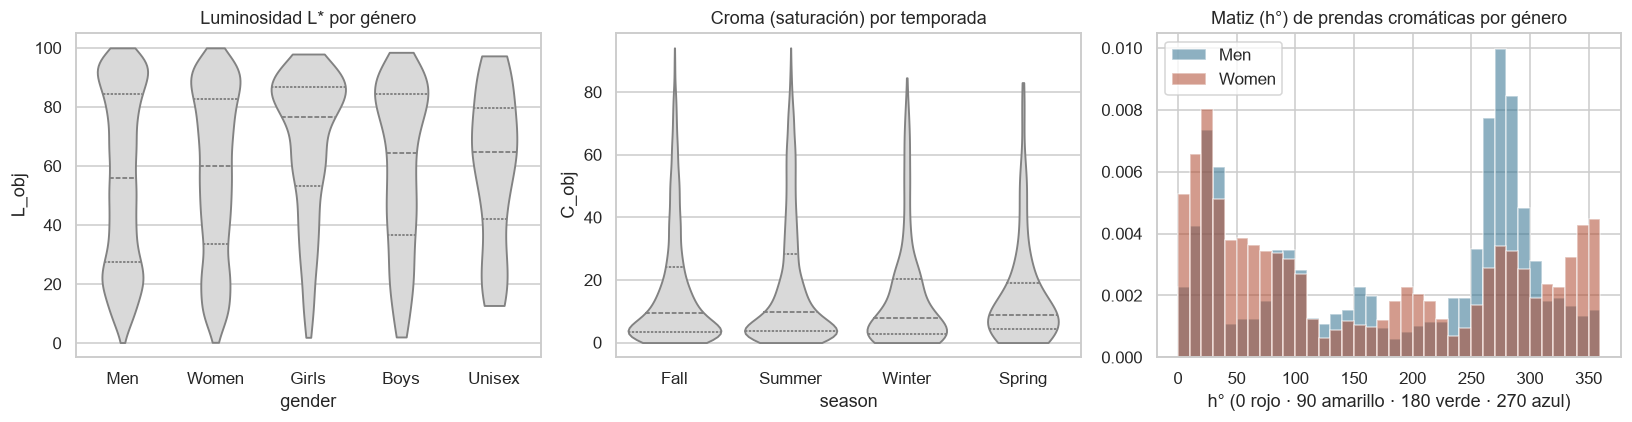

Kruskal-Wallis L_obj ~ gender: p = 3.5e-15  · medianas: {'Boys': 64.3, 'Girls': 76.6, 'Men': 55.9, 'Unisex': 64.6, 'Women': 59.9}
Kruskal-Wallis C_obj ~ season: p = 3.5e-07  · medianas: {'Fall': 9.4, 'Spring': 8.9, 'Summer': 9.6, 'Winter': 7.9}


Kruskal-Wallis C_obj ~ usage: p = 4.3e-87  · medianas: {'Casual': 9.4, 'Ethnic': 16.4, 'Formal': 5.6, 'Party': 1.5, 'Smart Casual': 6.7, 'Sports': 5.5, 'Travel': 3.0}


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cr = base[~base["multicolor"].astype(bool)]
sns.violinplot(data=cr, x="gender", y="L_obj", ax=axes[0], inner="quartile", color="0.85", cut=0)
axes[0].set_title("Luminosidad L* por género")
sns.violinplot(data=cr, x="season", y="C_obj", ax=axes[1], inner="quartile", color="0.85", cut=0)
axes[1].set_title("Croma (saturación) por temporada")
for g, col in [("Men", "#2F6F8F"), ("Women", "#B04A2F")]:
    axes[2].hist(cr.loc[(cr["gender"] == g) & (cr["C_obj"] > 10), "hue"], bins=36, range=(0, 360), alpha=.55, color=col, label=g, density=True)
axes[2].set(title="Matiz (h°) de prendas cromáticas por género", xlabel="h° (0 rojo · 90 amarillo · 180 verde · 270 azul)"); axes[2].legend()
plt.tight_layout(); guardar("p3_lab_metadatos"); plt.show()
for var, grupo in [("L_obj", "gender"), ("C_obj", "season"), ("C_obj", "usage")]:
    muestras = [g[var].values for _, g in cr.groupby(grupo) if len(g) > 30]
    print(f"Kruskal-Wallis {var} ~ {grupo}: p = {kruskal(*muestras).pvalue:.1e}  · medianas:",
          cr.groupby(grupo)[var].median().round(1).to_dict())

**Lectura para el negocio.** El color depende del tipo de prenda y del género (por ejemplo, la ropa interior y los *kurtas* tienen paletas propias), así que el modelo podría usar esos metadatos como **atajo**. En el contexto real el área comercial **no recibe metadatos fiables**, solo la foto. Por eso los modelos no usan los metadatos como entrada, y la evaluación se desagrega por género y subcategoría para comprobar que el error no depende de ellos (notebook 05).

## 3. Análisis cualitativo de las imágenes

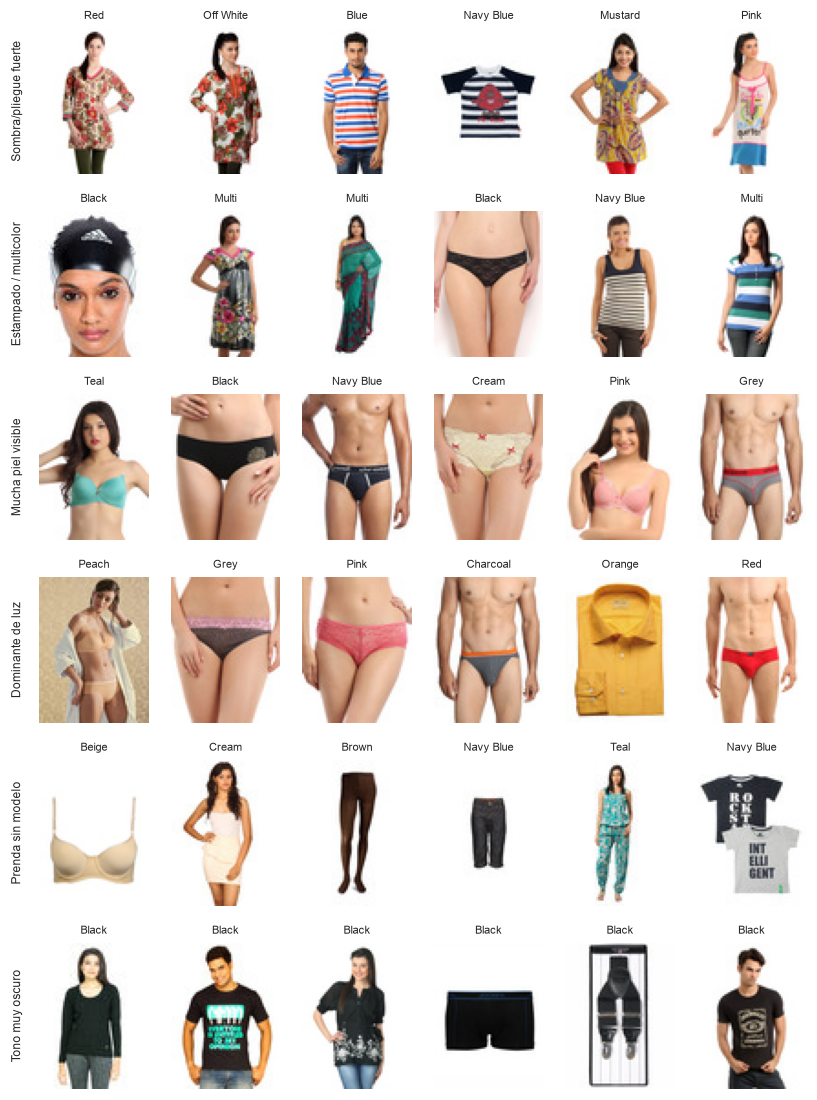

In [8]:
casos = {
    "Sombra/pliegue fuerte": t.nlargest(400, "L_std_prenda").sample(6, random_state=1).index,
    "Estampado / multicolor": t[t["multicolor"]].sample(6, random_state=2).index,
    "Mucha piel visible": t.nlargest(400, "frac_piel").sample(6, random_state=3).index,
    "Dominante de luz": t.nlargest(200, "croma_fondo").sample(6, random_state=4).index,
    "Prenda sin modelo": t[t["fuente_mascara"] == "umbral_fondo"].sample(6, random_state=5).index,
    "Tono muy oscuro": t[t["L_obj"] < 20].sample(6, random_state=6).index,
}
fig, axes = plt.subplots(len(casos), 6, figsize=(9, 2.1 * len(casos)))
for fila, (tit, ids) in zip(axes, casos.items()):
    for ax, pid in zip(fila, ids):
        ax.imshow(decodificar(bytes_por_id[pid])); ax.set_title(t.at[pid, "baseColour"], fontsize=7); ax.axis("off")
    fila[0].text(-0.15, 0.5, tit, transform=fila[0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
guardar("p3_cualitativo"); plt.show()

**Observaciones cualitativas.**
* Los **tonos oscuros** (Black, Navy Blue, Charcoal) tienen poca información de matiz: pequeñas diferencias de exposición los mueven entre sí. Es el caso más difícil para cualquier modelo.
* En las **sombras y pliegues** una misma tela abarca 20–30 unidades de L\*; el promedio de la prenda subestima su luminosidad real, y el grupo dominante de k-means lo corrige.
* Las **prendas con estampado** o rayas no tienen un color único: la paleta es la representación correcta.
* Las **prendas sin modelo** (ropa interior, prendas dobladas) son las que el parser no segmenta; ahí sigue siendo válida la máscara contra el fondo, porque no hay persona.
* Algunas fotos tienen una **dominante cálida o fría** visible en el fondo; sin balance de blancos ese sesgo pasaría al color medido.